In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

df = pd.read_csv("Hourly total-sales dataset.csv")

df.head()

,Hours_Start,Sale_Day,Sale_Hour,Transaction_Count,Total_Quantity,Hourly_Sales
0,2024-12-19 16:00:00.000,2024-12-19,16,3,3.0,0.03
1,2024-12-25 12:00:00.000,2024-12-25,12,1,4.0,6.36
2,2024-12-25 13:00:00.000,2024-12-25,13,6,8.0,15.60
3,2024-12-25 14:00:00.000,2024-12-25,14,2,4.0,35.10
4,2024-12-25 15:00:00.000,2024-12-25,15,4,6.0,15.56


In [3]:
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])

df = df.sort_values('Hours_Start').reset_index(drop=True)

print(df.shape)
print(df['Hours_Start'].min())
print(df['Hours_Start'].max())

(8616, 6)
2024-12-19 16:00:00
2026-07-15 16:00:00


In [4]:
df['hour'] = df['Hours_Start'].dt.hour
df['day_of_week'] = df['Hours_Start'].dt.dayofweek
df['day_of_month'] = df['Hours_Start'].dt.day
df['month'] = df['Hours_Start'].dt.month
df['year'] = df['Hours_Start'].dt.year
df['is_weekend'] = (df['day_of_week'] >= 5).astype(int)

In [5]:
df['lag_1'] = df['Hourly_Sales'].shift(1)
df['lag_24'] = df['Hourly_Sales'].shift(24)
df['lag_168'] = df['Hourly_Sales'].shift(168)

df['rolling_mean_24'] = (
    df['Hourly_Sales']
    .shift(1)
    .rolling(24)
    .mean()
)

df['rolling_mean_168'] = (
    df['Hourly_Sales']
    .shift(1)
    .rolling(168)
    .mean()
)

In [6]:
df['days_to_month_end'] = (
    df['Hours_Start'].dt.days_in_month -
    df['Hours_Start'].dt.day
)

df['is_month_end'] = (
    df['days_to_month_end'] <= 2
).astype(int)

In [7]:
# Make sure datetime is correct
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])

# Sort chronologically
df = df.sort_values('Hours_Start').reset_index(drop=True)

print("First:", df['Hours_Start'].min())
print("Last:", df['Hours_Start'].max())
print("Rows:", len(df))

# Difference between consecutive records
df['time_gap'] = df['Hours_Start'].diff()

print(df['time_gap'].value_counts().head(15))

First: 2024-12-19 16:00:00
Last: 2026-07-15 16:00:00
Rows: 8616
0 days 01:00:00    8005
0 days 10:00:00     274
0 days 09:00:00     224
0 days 11:00:00      58
0 days 02:00:00      41
0 days 12:00:00       6
0 days 13:00:00       2
0 days 08:00:00       2
5 days 20:00:00       1
0 days 14:00:00       1
0 days 03:00:00       1
Name: time_gap, dtype: int64


In [8]:
print("Gaps greater than 1 hour:",
      (df['time_gap'] > pd.Timedelta(hours=1)).sum())

Gaps greater than 1 hour: 610


In [9]:
df['lag_1'] = df['Hourly_Sales'].shift(1)
df['lag_24'] = df['Hourly_Sales'].shift(24)
df['lag_168'] = df['Hourly_Sales'].shift(168)

In [10]:
df['days_to_month_end'] = (
    df['Hours_Start'].dt.days_in_month -
    df['Hours_Start'].dt.day
)

df['is_month_end'] = (
    df['days_to_month_end'] <= 2
).astype(int)

In [11]:
split_index = int(len(df) * 0.8)

train = df.iloc[:split_index].copy()
test = df.iloc[split_index:].copy()

print("Training:", train.shape)
print("Testing:", test.shape)

print("\nTraining period:")
print(train['Hours_Start'].min(), "to", train['Hours_Start'].max())

print("\nTesting period:")
print(test['Hours_Start'].min(), "to", test['Hours_Start'].max())

Training: (6892, 20)
Testing: (1724, 20)

Training period:
2024-12-19 16:00:00 to 2026-03-26 07:00:00

Testing period:
2026-03-26 08:00:00 to 2026-07-15 16:00:00


In [12]:
# Make sure data is sorted by time
df = df.sort_values('Hours_Start').reset_index(drop=True)

# Calculate time difference between consecutive rows
df['time_gap'] = df['Hours_Start'].diff()

print("Time gap frequencies:")
print(df['time_gap'].value_counts().sort_index())

print("\nNumber of gaps greater than 1 hour:")
print((df['time_gap'] > pd.Timedelta(hours=1)).sum())

Time gap frequencies:
0 days 01:00:00    8005
0 days 02:00:00      41
0 days 03:00:00       1
0 days 08:00:00       2
0 days 09:00:00     224
0 days 10:00:00     274
0 days 11:00:00      58
0 days 12:00:00       6
0 days 13:00:00       2
0 days 14:00:00       1
5 days 20:00:00       1
Name: time_gap, dtype: int64

Number of gaps greater than 1 hour:
610


In [13]:
# train_test_split(df, test_size=0.2, random_state=42)

In [14]:
# Show some of the missing/gap periods
gaps = df[df['time_gap'] > pd.Timedelta(hours=1)]

gaps[['Hours_Start', 'time_gap']].head(20)

,Hours_Start,time_gap
1,2024-12-25 12:00:00,5 days 20:00:00
11,2024-12-26 11:00:00,0 days 14:00:00
20,2024-12-27 08:00:00,0 days 13:00:00
23,2024-12-27 12:00:00,0 days 02:00:00
30,2024-12-27 20:00:00,0 days 02:00:00
33,2024-12-28 09:00:00,0 days 11:00:00
47,2024-12-29 08:00:00,0 days 10:00:00
51,2024-12-29 13:00:00,0 days 02:00:00
58,2024-12-30 08:00:00,0 days 13:00:00
60,2024-12-30 11:00:00,0 days 02:00:00


In [15]:
df = df.drop(
    columns=[
        'lag_1',
        'lag_24',
        'lag_168',
        'rolling_mean_24',
        'rolling_mean_168'
    ],
    errors='ignore'
)

In [16]:
# Make timestamp unique and chronological
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])
df = df.sort_values('Hours_Start').reset_index(drop=True)

# Create lookup series
sales_lookup = df.set_index('Hours_Start')['Hourly_Sales']

df['lag_1h'] = (
    df['Hours_Start'] - pd.Timedelta(hours=1)
).map(sales_lookup)

df['lag_24h'] = (
    df['Hours_Start'] - pd.Timedelta(hours=24)
).map(sales_lookup)

df['lag_7d'] = (
    df['Hours_Start'] - pd.Timedelta(days=7)
).map(sales_lookup)

In [17]:
df[
    ['Hours_Start', 'Hourly_Sales',
     'lag_1h', 'lag_24h', 'lag_7d']
].head(30)

,Hours_Start,Hourly_Sales,lag_1h,lag_24h,lag_7d
0,2024-12-19 16:00:00,0.03,NaN,NaN,NaN
1,2024-12-25 12:00:00,6.36,NaN,NaN,NaN
2,2024-12-25 13:00:00,15.60,6.36,NaN,NaN
3,2024-12-25 14:00:00,35.10,15.60,NaN,NaN
4,2024-12-25 15:00:00,15.56,35.10,NaN,NaN
5,2024-12-25 16:00:00,2.58,15.56,NaN,NaN
6,2024-12-25 17:00:00,22.40,2.58,NaN,NaN
7,2024-12-25 18:00:00,3.05,22.40,NaN,NaN
8,2024-12-25 19:00:00,34.93,3.05,NaN,NaN
9,2024-12-25 20:00:00,46.31,34.93,NaN,NaN


In [18]:
print("Missing lag_1h:")
print(df['lag_1h'].isna().sum())

print("\nMissing lag_24h:")
print(df['lag_24h'].isna().sum())

print("\nMissing lag_7d:")
print(df['lag_7d'].isna().sum())

Missing lag_1h:
611

Missing lag_24h:
303

Missing lag_7d:
285


In [19]:
df.dropna()


,Hours_Start,Sale_Day,Sale_Hour,Transaction_Count,Total_Quantity,Hourly_Sales,hour,day_of_week,day_of_month,month,year,is_weekend,days_to_month_end,is_month_end,time_gap,lag_1h,lag_24h,lag_7d
16,2024-12-26 16:00:00,2024-12-26,16,5,8.0,16.19,16,3,26,12,2024,0,5,0,0 days 01:00:00,23.20,2.58,0.03
90,2025-01-01 12:00:00,2025-01-01,12,1,1.0,1.99,12,2,1,1,2025,0,30,0,0 days 01:00:00,14.25,4.79,6.36
91,2025-01-01 13:00:00,2025-01-01,13,2,6.0,7.92,13,2,1,1,2025,0,30,0,0 days 01:00:00,1.99,22.51,15.60
92,2025-01-01 14:00:00,2025-01-01,14,1,1.0,1.69,14,2,1,1,2025,0,30,0,0 days 01:00:00,7.92,22.66,35.10
93,2025-01-01 15:00:00,2025-01-01,15,3,22.0,32.81,15,2,1,1,2025,0,30,0,0 days 01:00:00,1.69,4.43,15.56
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
8611,2026-07-15 12:00:00,2026-07-15,12,16,33.0,64.18,12,2,15,7,2026,0,16,0,0 days 01:00:00,203.36,204.60,100.30
8612,2026-07-15 13:00:00,2026-07-15,13,20,67.0,217.43,13,2,15,7,2026,0,16,0,0 days 01:00:00,64.18,105.88,105.60
8613,2026-07-15 14:00:00,2026-07-15,14,16,37.0,81.19,14,2,15,7,2026,0,16,0,0 days 01:00:00,217.43,64.52,159.56
8614,2026-07-15 15:00:00,2026-07-15,15,20,40.0,119.57,15,2,15,7,2026,0,16,0,0 days 01:00:00,81.19,163.78,52.07


In [20]:
baseline_df = df.dropna(subset=['lag_7d']).copy()

print("Original rows:", len(df))
print("Baseline rows:", len(baseline_df))
print("Rows removed:", len(df) - len(baseline_df))

Original rows: 8616
Baseline rows: 8331
Rows removed: 285


In [21]:
split_index = int(len(baseline_df) * 0.8)

train = baseline_df.iloc[:split_index].copy()
test = baseline_df.iloc[split_index:].copy()

print("Training rows:", len(train))
print("Testing rows:", len(test))

print("\nTraining period:")
print(train['Hours_Start'].min(), "to", train['Hours_Start'].max())

print("\nTesting period:")
print(test['Hours_Start'].min(), "to", test['Hours_Start'].max())

Training rows: 6664
Testing rows: 1667

Training period:
2024-12-26 16:00:00 to 2026-03-28 12:00:00

Testing period:
2026-03-28 13:00:00 to 2026-07-15 16:00:00


In [22]:
y_test = test['Hourly_Sales']
baseline_pred = test['lag_7d']

In [23]:
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

baseline_mae = mean_absolute_error(
    y_test,
    baseline_pred
)

baseline_rmse = np.sqrt(
    mean_squared_error(
        y_test,
        baseline_pred
    )
)

print("Naive 7-Day Baseline")
print("--------------------")
print("MAE:", round(baseline_mae, 2))
print("RMSE:", round(baseline_rmse, 2))

Naive 7-Day Baseline
--------------------
MAE: 39.56
RMSE: 61.56


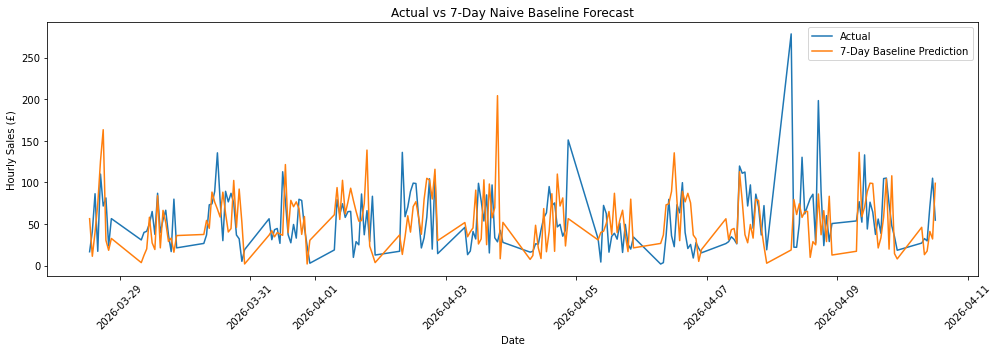

In [24]:
plt.figure(figsize=(14, 5))

sample = test.head(200)

plt.plot(
    sample['Hours_Start'],
    sample['Hourly_Sales'],
    label='Actual'
)

plt.plot(
    sample['Hours_Start'],
    sample['lag_7d'],
    label='7-Day Baseline Prediction'
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title('Actual vs 7-Day Naive Baseline Forecast')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [25]:
from prophet import Prophet

In [26]:
# !pip install prophet

In [27]:
prophet_data = df[['Hours_Start', 'Hourly_Sales']].copy()

prophet_data = prophet_data.rename(columns={
    'Hours_Start': 'ds',
    'Hourly_Sales': 'y'
})

prophet_data = prophet_data.sort_values('ds').reset_index(drop=True)

prophet_data.head()

,ds,y
0,2024-12-19 16:00:00,0.03
1,2024-12-25 12:00:00,6.36
2,2024-12-25 13:00:00,15.60
3,2024-12-25 14:00:00,35.10
4,2024-12-25 15:00:00,15.56


In [28]:
split_index = int(len(prophet_data) * 0.8)

prophet_train = prophet_data.iloc[:split_index].copy()
prophet_test = prophet_data.iloc[split_index:].copy()

print("Training:", prophet_train.shape)
print("Testing:", prophet_test.shape)

print("\nTraining period:")
print(prophet_train['ds'].min(), "to", prophet_train['ds'].max())

print("\nTesting period:")
print(prophet_test['ds'].min(), "to", prophet_test['ds'].max())

Training: (6892, 2)
Testing: (1724, 2)

Training period:
2024-12-19 16:00:00 to 2026-03-26 07:00:00

Testing period:
2026-03-26 08:00:00 to 2026-07-15 16:00:00


In [29]:
model_prophet = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=True
)

model_prophet.fit(prophet_train)

09:48:37 - cmdstanpy - INFO - Chain [1] start processing
09:48:38 - cmdstanpy - INFO - Chain [1] done processing


In [30]:
future = prophet_test[['ds']].copy()

prophet_forecast = model_prophet.predict(future)

In [31]:
prophet_forecast[
    ['ds', 'yhat', 'yhat_lower', 'yhat_upper']
].head()

,ds,yhat,yhat_lower,yhat_upper
0,2026-03-26 08:00:00,35.495092,-6.895489,74.230675
1,2026-03-26 09:00:00,36.863350,-3.903927,77.421625
2,2026-03-26 10:00:00,42.715516,3.243805,83.367762
3,2026-03-26 11:00:00,50.109618,11.092804,90.060206
4,2026-03-26 12:00:00,53.627118,14.233446,95.115169


In [32]:
prophet_actual = prophet_test['y'].values
prophet_pred = prophet_forecast['yhat'].values

prophet_mae = mean_absolute_error(
    prophet_actual,
    prophet_pred
)

prophet_rmse = np.sqrt(
    mean_squared_error(
        prophet_actual,
        prophet_pred
    )
)

print("Prophet - Without Payday Features")
print("---------------------------------")
print("MAE:", round(prophet_mae, 2))
print("RMSE:", round(prophet_rmse, 2))

Prophet - Without Payday Features
---------------------------------
MAE: 44.13
RMSE: 65.24


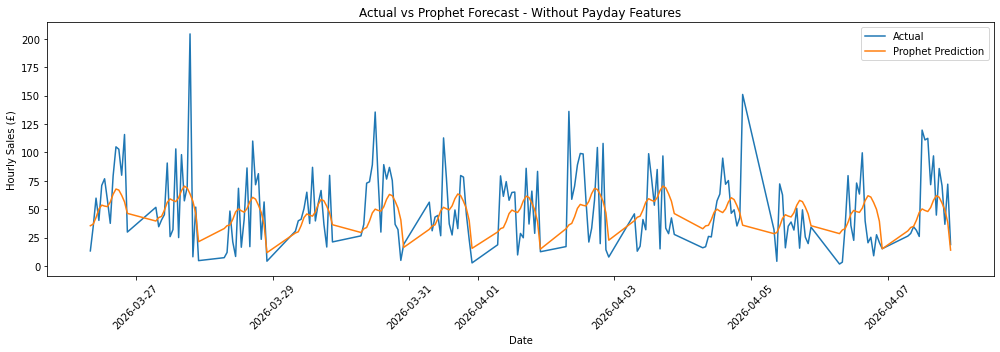

In [33]:
plt.figure(figsize=(14, 5))

n = 200

plt.plot(
    prophet_test['ds'].iloc[:n],
    prophet_test['y'].iloc[:n],
    label='Actual'
)

plt.plot(
    prophet_test['ds'].iloc[:n],
    prophet_forecast['yhat'].iloc[:n],
    label='Prophet Prediction'
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title('Actual vs Prophet Forecast - Without Payday Features')
plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [34]:
# here i try after pay day

In [35]:
# Start from the Prophet dataset
prophet_payday = prophet_data.copy()

# Days remaining until the end of each month
prophet_payday['days_to_month_end'] = (
    prophet_payday['ds'].dt.days_in_month -
    prophet_payday['ds'].dt.day
)

# Payday window:
# last 2 days of the month + first 2 days of next month
prophet_payday['is_payday_period'] = (
    (prophet_payday['days_to_month_end'] <= 1) |
    (prophet_payday['ds'].dt.day <= 2)
).astype(int)

prophet_payday[
    ['ds', 'y', 'days_to_month_end', 'is_payday_period']
].head(30)

,ds,y,days_to_month_end,is_payday_period
0,2024-12-19 16:00:00,0.03,12,0
1,2024-12-25 12:00:00,6.36,6,0
2,2024-12-25 13:00:00,15.60,6,0
3,2024-12-25 14:00:00,35.10,6,0
4,2024-12-25 15:00:00,15.56,6,0
5,2024-12-25 16:00:00,2.58,6,0
6,2024-12-25 17:00:00,22.40,6,0
7,2024-12-25 18:00:00,3.05,6,0
8,2024-12-25 19:00:00,34.93,6,0
9,2024-12-25 20:00:00,46.31,6,0


In [36]:
print(
    prophet_payday['is_payday_period'].value_counts()
)

prophet_payday[
    prophet_payday['is_payday_period'] == 1
][['ds', 'y', 'is_payday_period']].head(30)

0    7460
1    1156
Name: is_payday_period, dtype: int64


,ds,y,is_payday_period
58,2024-12-30 08:00:00,6.00,1
59,2024-12-30 09:00:00,24.37,1
60,2024-12-30 11:00:00,8.19,1
61,2024-12-30 12:00:00,26.06,1
62,2024-12-30 13:00:00,3.19,1
63,2024-12-30 14:00:00,22.77,1
64,2024-12-30 15:00:00,75.51,1
65,2024-12-30 16:00:00,30.26,1
66,2024-12-30 18:00:00,27.80,1
67,2024-12-30 19:00:00,11.82,1


In [37]:
split_index = int(len(prophet_payday) * 0.8)

payday_train = prophet_payday.iloc[:split_index].copy()
payday_test = prophet_payday.iloc[split_index:].copy()

print("Training:", payday_train.shape)
print("Testing:", payday_test.shape)

print(
    payday_train['ds'].min(),
    "to",
    payday_train['ds'].max()
)

print(
    payday_test['ds'].min(),
    "to",
    payday_test['ds'].max()
)

Training: (6892, 4)
Testing: (1724, 4)
2024-12-19 16:00:00 to 2026-03-26 07:00:00
2026-03-26 08:00:00 to 2026-07-15 16:00:00


In [38]:
model_prophet_payday = Prophet(
    daily_seasonality=True,
    weekly_seasonality=True,
    yearly_seasonality=True
)

model_prophet_payday.add_regressor(
    'is_payday_period'
)

model_prophet_payday.fit(
    payday_train[
        ['ds', 'y', 'is_payday_period']
    ]
)

09:48:41 - cmdstanpy - INFO - Chain [1] start processing
09:48:43 - cmdstanpy - INFO - Chain [1] done processing


In [39]:
future_payday = payday_test[
    ['ds', 'is_payday_period']
].copy()

forecast_payday = model_prophet_payday.predict(
    future_payday
)

In [40]:
payday_actual = payday_test['y'].values
payday_pred = forecast_payday['yhat'].values

payday_mae = mean_absolute_error(
    payday_actual,
    payday_pred
)

payday_rmse = np.sqrt(
    mean_squared_error(
        payday_actual,
        payday_pred
    )
)

print("Prophet - WITH Payday Feature")
print("--------------------------------")
print("MAE:", round(payday_mae, 2))
print("RMSE:", round(payday_rmse, 2))

Prophet - WITH Payday Feature
--------------------------------
MAE: 35.52
RMSE: 53.56


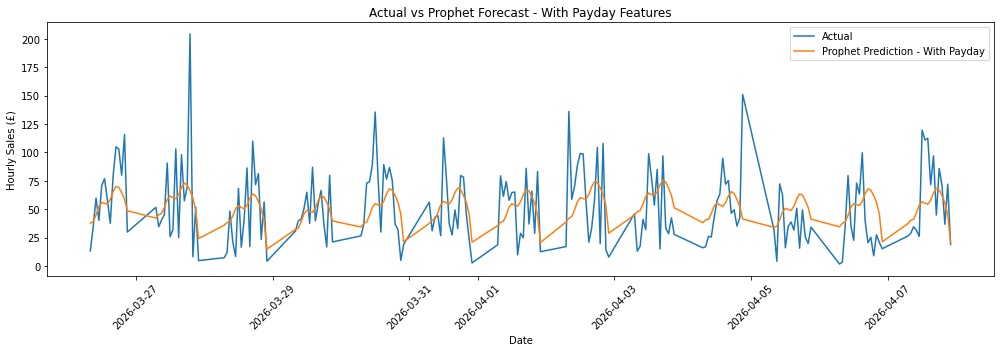

In [41]:
import matplotlib.pyplot as plt

# Number of observations to display
n = 200

plt.figure(figsize=(14, 5))

# Actual sales
plt.plot(
    payday_test['ds'].iloc[:n],
    payday_test['y'].iloc[:n],
    label='Actual'
)

# Prophet prediction WITH payday
plt.plot(
    payday_test['ds'].iloc[:n],
    forecast_payday['yhat'].iloc[:n],
    label='Prophet Prediction - With Payday'
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title('Actual vs Prophet Forecast - With Payday Features')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

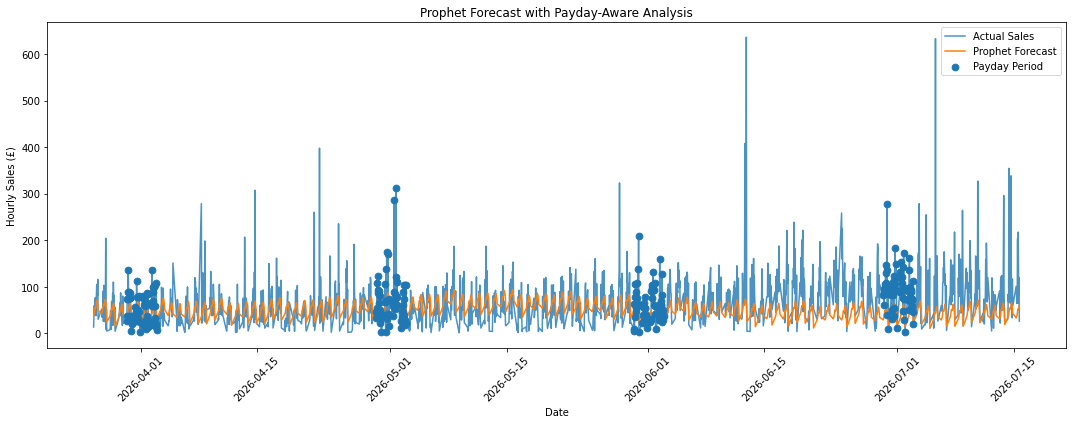

In [42]:
import matplotlib.pyplot as plt

# Use the full test period
plot_df = payday_test.copy()
plot_forecast = forecast_payday.copy()

plt.figure(figsize=(15, 6))

# Actual sales
plt.plot(
    plot_df['ds'],
    plot_df['y'],
    label='Actual Sales',
    alpha=0.8
)

# Prophet prediction
plt.plot(
    plot_forecast['ds'],
    plot_forecast['yhat'],
    label='Prophet Forecast'
)

# Highlight observations classified as payday period
payday_rows = plot_df[plot_df['is_payday_period'] == 1]

plt.scatter(
    payday_rows['ds'],
    payday_rows['y'],
    s=45,
    label='Payday Period',
    zorder=5
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title('Prophet Forecast with Payday-Aware Analysis')

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [43]:
payday_analysis = (
    payday_test
    .groupby('is_payday_period')['y']
    .agg(['count', 'mean', 'median', 'std'])
)

payday_analysis.index = ['Non-Payday', 'Payday Period']

print(payday_analysis)

               count       mean  median        std
Non-Payday      1473  70.660978   61.11  52.417545
Payday Period    251  70.684263   64.78  46.265899


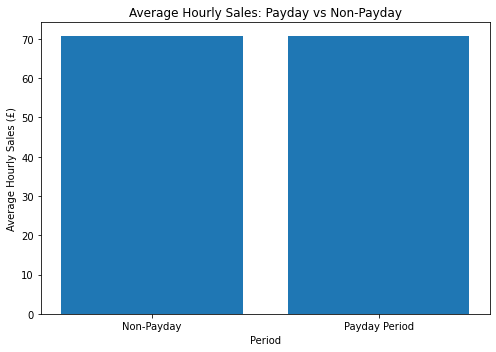

In [44]:
payday_avg = (
    payday_test
    .groupby('is_payday_period')['y']
    .mean()
)

plt.figure(figsize=(7,5))

plt.bar(
    ['Non-Payday', 'Payday Period'],
    payday_avg.values
)

plt.ylabel('Average Hourly Sales (£)')
plt.xlabel('Period')
plt.title('Average Hourly Sales: Payday vs Non-Payday')

plt.tight_layout()
plt.show()

In [45]:
print(df.columns.tolist())

['Hours_Start', 'Sale_Day', 'Sale_Hour', 'Transaction_Count', 'Total_Quantity', 'Hourly_Sales', 'hour', 'day_of_week', 'day_of_month', 'month', 'year', 'is_weekend', 'days_to_month_end', 'is_month_end', 'time_gap', 'lag_1h', 'lag_24h', 'lag_7d']


In [46]:
print(df[['Hours_Start', 'days_to_month_end', 'is_payday_period']].head(20))

print("\nUnique days_to_month_end values:")
print(sorted(df['days_to_month_end'].dropna().unique())[:40])

print("\nDate range:")
print(df['Hours_Start'].min())
print(df['Hours_Start'].max())

KeyError: "['is_payday_period'] not in index"

In [47]:
print(
    df[['Hours_Start', 'days_to_month_end']]
    .head(20)
)

print("\nUnique days_to_month_end:")
print(sorted(df['days_to_month_end'].dropna().unique()))

print("\nDate range:")
print("Start:", df['Hours_Start'].min())
print("End:", df['Hours_Start'].max())

           Hours_Start  days_to_month_end
0  2024-12-19 16:00:00                 12
1  2024-12-25 12:00:00                  6
2  2024-12-25 13:00:00                  6
3  2024-12-25 14:00:00                  6
4  2024-12-25 15:00:00                  6
5  2024-12-25 16:00:00                  6
6  2024-12-25 17:00:00                  6
7  2024-12-25 18:00:00                  6
8  2024-12-25 19:00:00                  6
9  2024-12-25 20:00:00                  6
10 2024-12-25 21:00:00                  6
11 2024-12-26 11:00:00                  5
12 2024-12-26 12:00:00                  5
13 2024-12-26 13:00:00                  5
14 2024-12-26 14:00:00                  5
15 2024-12-26 15:00:00                  5
16 2024-12-26 16:00:00                  5
17 2024-12-26 17:00:00                  5
18 2024-12-26 18:00:00                  5
19 2024-12-26 19:00:00                  5

Unique days_to_month_end:
[0, 1, 2, 3, 4, 5, 6, 7, 8, 9, 10, 11, 12, 13, 14, 15, 16, 17, 18, 19, 20, 21, 22, 23, 24, 

In [48]:
df['is_payday_period'] = (
    df['days_to_month_end'] <= 2
).astype(int)

print(df[
    ['Hours_Start',
     'days_to_month_end',
     'is_payday_period']
].head(20))

           Hours_Start  days_to_month_end  is_payday_period
0  2024-12-19 16:00:00                 12                 0
1  2024-12-25 12:00:00                  6                 0
2  2024-12-25 13:00:00                  6                 0
3  2024-12-25 14:00:00                  6                 0
4  2024-12-25 15:00:00                  6                 0
5  2024-12-25 16:00:00                  6                 0
6  2024-12-25 17:00:00                  6                 0
7  2024-12-25 18:00:00                  6                 0
8  2024-12-25 19:00:00                  6                 0
9  2024-12-25 20:00:00                  6                 0
10 2024-12-25 21:00:00                  6                 0
11 2024-12-26 11:00:00                  5                 0
12 2024-12-26 12:00:00                  5                 0
13 2024-12-26 13:00:00                  5                 0
14 2024-12-26 14:00:00                  5                 0
15 2024-12-26 15:00:00                  

In [49]:
print(df['is_payday_period'].value_counts())

0    7748
1     868
Name: is_payday_period, dtype: int64


In [50]:
sorted(df['days_to_month_end'].dropna().unique())

[0,
 1,
 2,
 3,
 4,
 5,
 6,
 7,
 8,
 9,
 10,
 11,
 12,
 13,
 14,
 15,
 16,
 17,
 18,
 19,
 20,
 21,
 22,
 23,
 24,
 25,
 26,
 27,
 28,
 29,
 30]

In [51]:
# Make sure Hours_Start is datetime
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])

# Calendar day of month
df['day_of_month'] = df['Hours_Start'].dt.day

# Number of days in each month
df['days_in_month'] = df['Hours_Start'].dt.days_in_month

# Distance from month-end
# Negative = before month-end
# 0 = month-end
df['payday_distance'] = (
    df['day_of_month'] - df['days_in_month']
)

# First 3 days of the next month become +1, +2, +3
df.loc[df['day_of_month'] <= 3, 'payday_distance'] = \
    df.loc[df['day_of_month'] <= 3, 'day_of_month']

# Keep only -3 to +3 for payday-window analysis
payday_window = df[
    df['payday_distance'].between(-3, 3)
].copy()

print(
    payday_window[
        ['Hours_Start', 'Hourly_Sales', 'payday_distance']
    ].head(30)
)

print("\nCounts:")
print(
    payday_window['payday_distance']
    .value_counts()
    .sort_index()
)

           Hours_Start  Hourly_Sales  payday_distance
33 2024-12-28 09:00:00         11.86               -3
34 2024-12-28 10:00:00          7.57               -3
35 2024-12-28 11:00:00         11.18               -3
36 2024-12-28 12:00:00         61.17               -3
37 2024-12-28 13:00:00         10.85               -3
38 2024-12-28 14:00:00         27.55               -3
39 2024-12-28 15:00:00          4.57               -3
40 2024-12-28 16:00:00         46.64               -3
41 2024-12-28 17:00:00          8.37               -3
42 2024-12-28 18:00:00         59.07               -3
43 2024-12-28 19:00:00          6.54               -3
44 2024-12-28 20:00:00         20.04               -3
45 2024-12-28 21:00:00         26.51               -3
46 2024-12-28 22:00:00          1.89               -3
47 2024-12-29 08:00:00          9.57               -2
48 2024-12-29 09:00:00          9.32               -2
49 2024-12-29 10:00:00          2.69               -2
50 2024-12-29 11:00:00      

In [52]:
payday_effect = (
    payday_window
    .groupby('payday_distance')['Hourly_Sales']
    .agg(['count', 'mean', 'median', 'std'])
    .round(2)
)

print(payday_effect)

                 count   mean  median    std
payday_distance                             
-3                 293  56.73   50.38  40.04
-2                 288  54.55   51.08  35.77
-1                 290  56.51   45.82  47.84
 0                 290  52.95   45.44  36.19
 1                 287  55.43   47.62  42.65
 2                 289  50.31   44.05  35.24
 3                 292  51.52   44.91  38.34


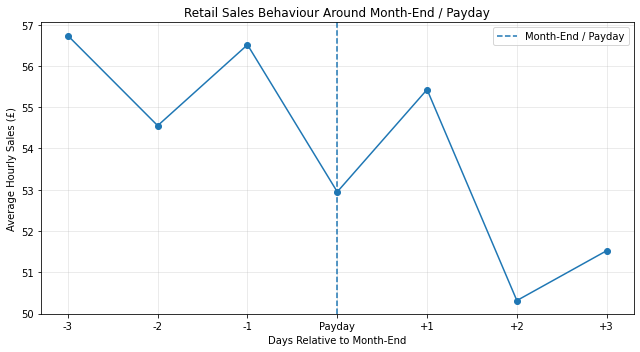

In [53]:
import matplotlib.pyplot as plt

payday_means = (
    payday_window
    .groupby('payday_distance')['Hourly_Sales']
    .mean()
)

plt.figure(figsize=(9, 5))

plt.plot(
    payday_means.index,
    payday_means.values,
    marker='o'
)

plt.axvline(
    x=0,
    linestyle='--',
    label='Month-End / Payday'
)

plt.xlabel('Days Relative to Month-End')
plt.ylabel('Average Hourly Sales (£)')
plt.title('Retail Sales Behaviour Around Month-End / Payday')
plt.xticks(
    [-3, -2, -1, 0, 1, 2, 3],
    ['-3', '-2', '-1', 'Payday', '+1', '+2', '+3']
)
plt.legend()
plt.grid(alpha=0.3)
plt.tight_layout()
plt.show()

In [54]:
from scipy.stats import mannwhitneyu

# Define payday window:
# 3 days before month-end through 3 days after
df['payday_window'] = (
    df['payday_distance'].between(-3, 3)
).astype(int)

payday_sales = df.loc[
    df['payday_window'] == 1,
    'Hourly_Sales'
].dropna()

non_payday_sales = df.loc[
    df['payday_window'] == 0,
    'Hourly_Sales'
].dropna()

print("Payday-window observations:", len(payday_sales))
print("Non-payday observations:", len(non_payday_sales))

print("\nAverage sales")
print("Payday window: £", round(payday_sales.mean(), 2))
print("Non-payday:    £", round(non_payday_sales.mean(), 2))

print("\nMedian sales")
print("Payday window: £", round(payday_sales.median(), 2))
print("Non-payday:    £", round(non_payday_sales.median(), 2))

# Mann-Whitney U test
stat, p_value = mannwhitneyu(
    payday_sales,
    non_payday_sales,
    alternative='two-sided'
)

print("\nMann-Whitney U Test")
print("-------------------")
print("Statistic:", round(stat, 2))
print("P-value:", round(p_value, 4))

if p_value < 0.05:
    print("Result: Statistically significant difference")
else:
    print("Result: No statistically significant difference")

Payday-window observations: 2029
Non-payday observations: 6587

Average sales
Payday window: £ 54.0
Non-payday:    £ 52.78

Median sales
Payday window: £ 47.16
Non-payday:    £ 44.52

Mann-Whitney U Test
-------------------
Statistic: 6855063.0
P-value: 0.0782
Result: No statistically significant difference


In [55]:
# %pip install xgboost

In [56]:
# If XGBoost is not installed:
# !pip install xgboost

from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np
import pandas as pd

# Make sure data are ordered by time
df = df.sort_values('Hours_Start').copy()

# Features available in BOTH models
base_features = [
    'hour',
    'day_of_week',
    'day_of_month',
    'month',
    'is_weekend',
    'lag_1h',
    'lag_24h',
    'lag_7d'
]

# Remove rows where required lag features are missing
model_df = df.dropna(
    subset=base_features + ['Hourly_Sales', 'payday_window']
).copy()

# Chronological 80/20 split
split_index = int(len(model_df) * 0.8)

train = model_df.iloc[:split_index].copy()
test = model_df.iloc[split_index:].copy()

print("Training observations:", len(train))
print("Testing observations:", len(test))

print("\nTraining period:")
print(train['Hours_Start'].min(), "to", train['Hours_Start'].max())

print("\nTesting period:")
print(test['Hours_Start'].min(), "to", test['Hours_Start'].max())

Training observations: 6123
Testing observations: 1531

Training period:
2024-12-26 16:00:00 to 2026-03-29 13:00:00

Testing period:
2026-03-29 14:00:00 to 2026-07-15 16:00:00


In [57]:
X_train = train[base_features]
X_test = test[base_features]

y_train = train['Hourly_Sales']
y_test = test['Hourly_Sales']

xgb_without_payday = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror'
)

xgb_without_payday.fit(X_train, y_train)

pred_without = xgb_without_payday.predict(X_test)

mae_without = mean_absolute_error(y_test, pred_without)
rmse_without = np.sqrt(
    mean_squared_error(y_test, pred_without)
)

print("XGBoost WITHOUT Payday")
print("----------------------")
print("MAE:", round(mae_without, 2))
print("RMSE:", round(rmse_without, 2))

XGBoost WITHOUT Payday
----------------------
MAE: 36.36
RMSE: 55.29


In [58]:
payday_features = base_features + ['payday_window']

X_train_payday = train[payday_features]
X_test_payday = test[payday_features]

xgb_with_payday = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror'
)

xgb_with_payday.fit(X_train_payday, y_train)

pred_with = xgb_with_payday.predict(X_test_payday)

mae_with = mean_absolute_error(y_test, pred_with)
rmse_with = np.sqrt(
    mean_squared_error(y_test, pred_with)
)

print("XGBoost WITH Payday")
print("-------------------")
print("MAE:", round(mae_with, 2))
print("RMSE:", round(rmse_with, 2))

XGBoost WITH Payday
-------------------
MAE: 36.37
RMSE: 55.25


In [59]:
comparison = pd.DataFrame({
    'Model': [
        'XGBoost Without Payday',
        'XGBoost With Payday'
    ],
    'MAE': [
        mae_without,
        mae_with
    ],
    'RMSE': [
        rmse_without,
        rmse_with
    ]
})

comparison[['MAE', 'RMSE']] = comparison[
    ['MAE', 'RMSE']
].round(2)

print(comparison)

                    Model    MAE   RMSE
0  XGBoost Without Payday  36.36  55.29
1     XGBoost With Payday  36.37  55.25


In [60]:
# Sort chronologically
df = df.sort_values('Hours_Start').copy()

# Ensure datetime
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])

# Create timestamp -> sales lookup
sales_lookup = df.set_index('Hours_Start')['Hourly_Sales']

# Exact 1-hour lag
df['lag_1h_exact'] = (
    df['Hours_Start'] - pd.Timedelta(hours=1)
).map(sales_lookup)

# Exact 24-hour lag
df['lag_24h_exact'] = (
    df['Hours_Start'] - pd.Timedelta(hours=24)
).map(sales_lookup)

# Exact 7-day lag
df['lag_7d_exact'] = (
    df['Hours_Start'] - pd.Timedelta(days=7)
).map(sales_lookup)

print("Total observations:", len(df))

print("\nMissing exact lags:")
print("1-hour lag:", df['lag_1h_exact'].isna().sum())
print("24-hour lag:", df['lag_24h_exact'].isna().sum())
print("7-day lag:", df['lag_7d_exact'].isna().sum())

df[
    ['Hours_Start', 'Hourly_Sales',
     'lag_1h_exact', 'lag_24h_exact', 'lag_7d_exact']
].head(30)

Total observations: 8616

Missing exact lags:
1-hour lag: 611
24-hour lag: 303
7-day lag: 285


,Hours_Start,Hourly_Sales,lag_1h_exact,lag_24h_exact,lag_7d_exact
0,2024-12-19 16:00:00,0.03,NaN,NaN,NaN
1,2024-12-25 12:00:00,6.36,NaN,NaN,NaN
2,2024-12-25 13:00:00,15.60,6.36,NaN,NaN
3,2024-12-25 14:00:00,35.10,15.60,NaN,NaN
4,2024-12-25 15:00:00,15.56,35.10,NaN,NaN
5,2024-12-25 16:00:00,2.58,15.56,NaN,NaN
6,2024-12-25 17:00:00,22.40,2.58,NaN,NaN
7,2024-12-25 18:00:00,3.05,22.40,NaN,NaN
8,2024-12-25 19:00:00,34.93,3.05,NaN,NaN
9,2024-12-25 20:00:00,46.31,34.93,NaN,NaN


In [61]:
# Correct features using exact time-based lags

base_features_exact = [
    'hour',
    'day_of_week',
    'day_of_month',
    'month',
    'is_weekend',
    'lag_1h_exact',
    'lag_24h_exact',
    'lag_7d_exact'
]

# Keep only observations with all required information
model_df_exact = df.dropna(
    subset=base_features_exact +
           ['Hourly_Sales', 'payday_window']
).copy()

# Make sure everything is chronological
model_df_exact = model_df_exact.sort_values('Hours_Start')

print("Original observations:", len(df))
print("Observations available for modelling:", len(model_df_exact))
print("Removed due to unavailable exact lags:",
      len(df) - len(model_df_exact))

print("\nModel period:")
print(model_df_exact['Hours_Start'].min(),
      "to",
      model_df_exact['Hours_Start'].max())

Original observations: 8616
Observations available for modelling: 7654
Removed due to unavailable exact lags: 962

Model period:
2024-12-26 16:00:00 to 2026-07-15 16:00:00


In [62]:
split_index = int(len(model_df_exact) * 0.8)

train_exact = model_df_exact.iloc[:split_index].copy()
test_exact = model_df_exact.iloc[split_index:].copy()

print("Training observations:", len(train_exact))
print("Testing observations:", len(test_exact))

print("\nTraining period:")
print(
    train_exact['Hours_Start'].min(),
    "to",
    train_exact['Hours_Start'].max()
)

print("\nTesting period:")
print(
    test_exact['Hours_Start'].min(),
    "to",
    test_exact['Hours_Start'].max()
)

Training observations: 6123
Testing observations: 1531

Training period:
2024-12-26 16:00:00 to 2026-03-29 13:00:00

Testing period:
2026-03-29 14:00:00 to 2026-07-15 16:00:00


In [63]:
from xgboost import XGBRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

X_train = train_exact[base_features_exact]
X_test = test_exact[base_features_exact]

y_train = train_exact['Hourly_Sales']
y_test = test_exact['Hourly_Sales']

xgb_without_payday_exact = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror'
)

xgb_without_payday_exact.fit(X_train, y_train)

pred_without_exact = xgb_without_payday_exact.predict(X_test)

mae_without_exact = mean_absolute_error(
    y_test,
    pred_without_exact
)

rmse_without_exact = np.sqrt(
    mean_squared_error(
        y_test,
        pred_without_exact
    )
)

print("XGBoost WITHOUT Payday - Exact Lags")
print("-----------------------------------")
print("MAE:", round(mae_without_exact, 2))
print("RMSE:", round(rmse_without_exact, 2))

XGBoost WITHOUT Payday - Exact Lags
-----------------------------------
MAE: 36.36
RMSE: 55.29


In [64]:
payday_features_exact = (
    base_features_exact + ['payday_window']
)

X_train_payday = train_exact[payday_features_exact]
X_test_payday = test_exact[payday_features_exact]

xgb_with_payday_exact = XGBRegressor(
    n_estimators=300,
    learning_rate=0.05,
    max_depth=5,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    objective='reg:squarederror'
)

xgb_with_payday_exact.fit(
    X_train_payday,
    y_train
)

pred_with_exact = xgb_with_payday_exact.predict(
    X_test_payday
)

mae_with_exact = mean_absolute_error(
    y_test,
    pred_with_exact
)

rmse_with_exact = np.sqrt(
    mean_squared_error(
        y_test,
        pred_with_exact
    )
)

print("XGBoost WITH Payday - Exact Lags")
print("--------------------------------")
print("MAE:", round(mae_with_exact, 2))
print("RMSE:", round(rmse_with_exact, 2))

XGBoost WITH Payday - Exact Lags
--------------------------------
MAE: 36.37
RMSE: 55.25


In [65]:
comparison_exact = pd.DataFrame({
    'Model': [
        'XGBoost Without Payday',
        'XGBoost With Payday'
    ],
    'MAE': [
        mae_without_exact,
        mae_with_exact
    ],
    'RMSE': [
        rmse_without_exact,
        rmse_with_exact
    ]
})

comparison_exact[['MAE', 'RMSE']] = (
    comparison_exact[['MAE', 'RMSE']].round(2)
)

print(comparison_exact)

                    Model    MAE   RMSE
0  XGBoost Without Payday  36.36  55.29
1     XGBoost With Payday  36.37  55.25


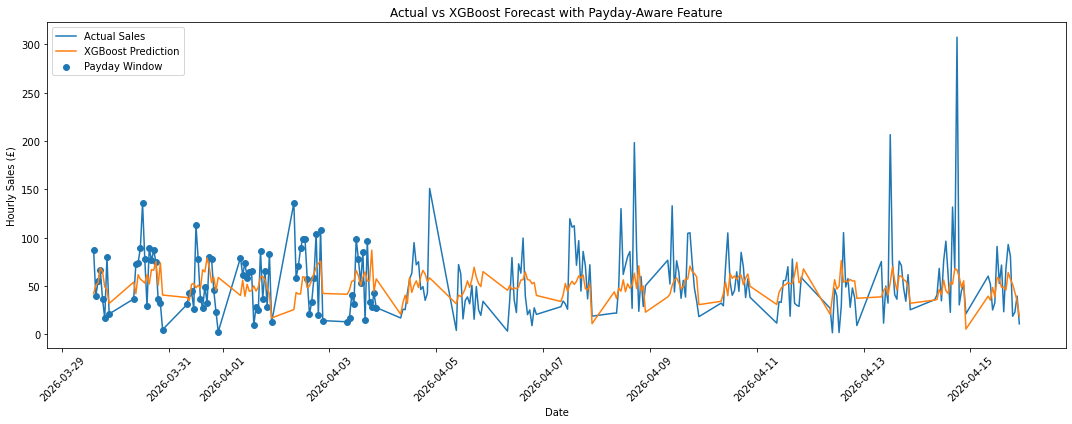

In [66]:
import matplotlib.pyplot as plt

# Create results dataframe
xgb_results = test_exact[
    ['Hours_Start', 'Hourly_Sales', 'payday_window']
].copy()

xgb_results['Predicted_Sales'] = pred_with_exact

# Plot first 250 test observations
plot_data = xgb_results.head(250)

plt.figure(figsize=(15, 6))

plt.plot(
    plot_data['Hours_Start'],
    plot_data['Hourly_Sales'],
    label='Actual Sales'
)

plt.plot(
    plot_data['Hours_Start'],
    plot_data['Predicted_Sales'],
    label='XGBoost Prediction'
)

# Highlight payday-window observations
payday_points = plot_data[
    plot_data['payday_window'] == 1
]

plt.scatter(
    payday_points['Hours_Start'],
    payday_points['Hourly_Sales'],
    label='Payday Window',
    s=35
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title(
    'Actual vs XGBoost Forecast with Payday-Aware Feature'
)

plt.legend()
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

In [67]:
!pip install shap

Defaulting to user installation because normal site-packages is not writeable


In [68]:
import shap
import matplotlib.pyplot as plt

# Create SHAP explainer using your XGBoost WITH-payday model
explainer = shap.TreeExplainer(xgb_with_payday)

# Calculate SHAP values for test data
shap_values = explainer.shap_values(X_test_payday)

print("SHAP analysis completed")
print("Test data shape:", X_test_payday.shape)

SHAP analysis completed
Test data shape: (1531, 9)


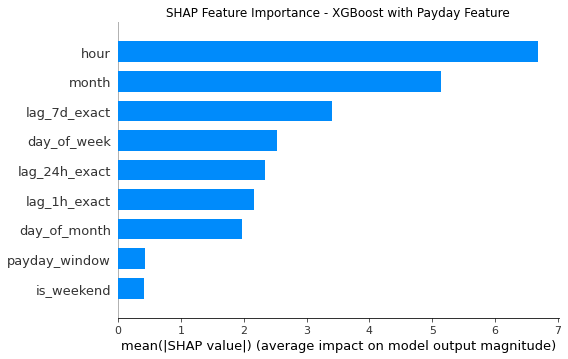

In [69]:
shap.summary_plot(
    shap_values,
    X_test_payday,
    plot_type="bar",
    show=False
)

plt.title("SHAP Feature Importance - XGBoost with Payday Feature")
plt.tight_layout()
plt.show()

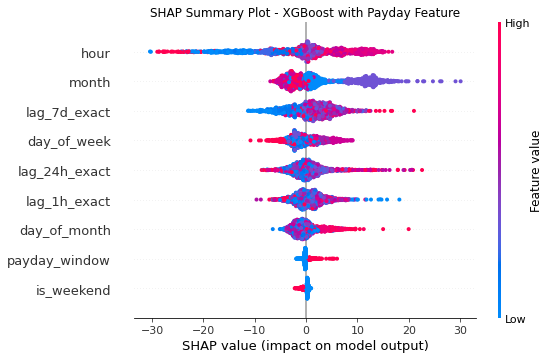

In [70]:
shap.summary_plot(
    shap_values,
    X_test_payday,
    show=False
)

plt.title("SHAP Summary Plot - XGBoost with Payday Feature")
plt.tight_layout()
plt.show()

In [71]:
import pandas as pd
import numpy as np

shap_importance = pd.DataFrame({
    'Feature': X_test_payday.columns,
    'Mean_Absolute_SHAP': np.abs(shap_values).mean(axis=0)
})

shap_importance = shap_importance.sort_values(
    'Mean_Absolute_SHAP',
    ascending=False
).reset_index(drop=True)

print(shap_importance)

         Feature  Mean_Absolute_SHAP
0           hour            6.674143
1          month            5.131071
2   lag_7d_exact            3.411893
3    day_of_week            2.521673
4  lag_24h_exact            2.340138
5   lag_1h_exact            2.170930
6   day_of_month            1.964918
7  payday_window            0.429092
8     is_weekend            0.416434


In [72]:
payday_shap = shap_importance[
    shap_importance['Feature'] == 'payday_window'
]

print("\nPayday SHAP importance:")
print(payday_shap)


Payday SHAP importance:
         Feature  Mean_Absolute_SHAP
7  payday_window            0.429092


In [73]:
total_importance = shap_importance['Mean_Absolute_SHAP'].sum()

shap_importance['Importance_Percentage'] = (
    shap_importance['Mean_Absolute_SHAP'] /
    total_importance * 100
)

print(
    shap_importance[
        ['Feature', 'Mean_Absolute_SHAP', 'Importance_Percentage']
    ].round(3)
)

         Feature  Mean_Absolute_SHAP  Importance_Percentage
0           hour               6.674                 26.632
1          month               5.131                 20.475
2   lag_7d_exact               3.412                 13.615
3    day_of_week               2.522                 10.062
4  lag_24h_exact               2.340                  9.338
5   lag_1h_exact               2.171                  8.663
6   day_of_month               1.965                  7.841
7  payday_window               0.429                  1.712
8     is_weekend               0.416                  1.662


In [74]:
pip install tensorflow

Defaulting to user installation because normal site-packages is not writeable



In [75]:
# STEP 1: Check TensorFlow and inspect data before LSTM

import tensorflow as tf
import numpy as np
import pandas as pd

print("TensorFlow version:", tf.__version__)

print("\nDataset shape:")
print(df.shape)

print("\nColumns:")
print(df.columns.tolist())

print("\nDate range:")
print(df['Hours_Start'].min(), "to", df['Hours_Start'].max())

print("\nHourly Sales summary:")
print(df['Hourly_Sales'].describe())

print("\nMissing values:")
print(df.isnull().sum())

TensorFlow version: 2.10.0

Dataset shape:
(8616, 25)

Columns:
['Hours_Start', 'Sale_Day', 'Sale_Hour', 'Transaction_Count', 'Total_Quantity', 'Hourly_Sales', 'hour', 'day_of_week', 'day_of_month', 'month', 'year', 'is_weekend', 'days_to_month_end', 'is_month_end', 'time_gap', 'lag_1h', 'lag_24h', 'lag_7d', 'is_payday_period', 'days_in_month', 'payday_distance', 'payday_window', 'lag_1h_exact', 'lag_24h_exact', 'lag_7d_exact']

Date range:
2024-12-19 16:00:00 to 2026-07-15 16:00:00

Hourly Sales summary:
count    8616.000000
mean       53.068483
std        40.003165
min         0.030000
25%        26.417500
50%        45.115000
75%        70.100000
max       636.510000
Name: Hourly_Sales, dtype: float64

Missing values:
Hours_Start            0
Sale_Day               0
Sale_Hour              0
Transaction_Count      0
Total_Quantity         0
Hourly_Sales           0
hour                   0
day_of_week            0
day_of_month           0
month                  0
year               

In [76]:
# =========================================================
# STEP 2: Analyse continuous hourly periods for LSTM
# =========================================================

# Make sure data is ordered chronologically
df = df.sort_values('Hours_Start').reset_index(drop=True)

# Ensure datetime format
df['Hours_Start'] = pd.to_datetime(df['Hours_Start'])

# Calculate difference between consecutive observations
df['lstm_time_gap'] = df['Hours_Start'].diff()

# Identify a break whenever the next record is NOT exactly 1 hour later
df['sequence_break'] = (
    df['lstm_time_gap'] != pd.Timedelta(hours=1)
).astype(int)

# First row starts a new sequence
df.loc[0, 'sequence_break'] = 1

# Give each continuous block an ID
df['sequence_id'] = df['sequence_break'].cumsum()

# Calculate length of each continuous block
sequence_lengths = df.groupby('sequence_id').size()

print("Total observations:", len(df))
print("Number of continuous sequences:", len(sequence_lengths))

print("\nSequence length statistics:")
print(sequence_lengths.describe())

print("\nLongest 10 continuous sequences:")
print(sequence_lengths.sort_values(ascending=False).head(10))

print("\nSequences with at least 6 consecutive hours:",
      (sequence_lengths >= 6).sum())

print("Sequences with at least 12 consecutive hours:",
      (sequence_lengths >= 12).sum())

print("Sequences with at least 24 consecutive hours:",
      (sequence_lengths >= 24).sum())

print("\nObservations belonging to sequences >= 6 hours:",
      sequence_lengths[sequence_lengths >= 6].sum())

print("Observations belonging to sequences >= 12 hours:",
      sequence_lengths[sequence_lengths >= 12].sum())

print("Observations belonging to sequences >= 24 hours:",
      sequence_lengths[sequence_lengths >= 24].sum())

Total observations: 8616
Number of continuous sequences: 611

Sequence length statistics:
count    611.000000
mean      14.101473
std        3.619100
min        1.000000
25%       14.000000
50%       15.000000
75%       16.000000
max       17.000000
dtype: float64

Longest 10 continuous sequences:
sequence_id
347    17
182    17
276    16
214    16
221    16
220    16
219    16
218    16
216    16
215    16
dtype: int64

Sequences with at least 6 consecutive hours: 568
Sequences with at least 12 consecutive hours: 545
Sequences with at least 24 consecutive hours: 0

Observations belonging to sequences >= 6 hours: 8521
Observations belonging to sequences >= 12 hours: 8315
Observations belonging to sequences >= 24 hours: 0


In [77]:
# =========================================================
# STEP 3: Prepare features for LSTM
# Model 1 = WITHOUT payday feature
# =========================================================

from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Features for LSTM WITHOUT payday
lstm_features = [
    'Hourly_Sales',
    'hour',
    'day_of_week',
    'day_of_month',
    'month',
    'is_weekend'
]

# Keep required columns
lstm_df = df[
    ['Hours_Start', 'sequence_id'] + lstm_features
].copy()

# Check for missing values
print("Missing values:")
print(lstm_df[lstm_features].isnull().sum())

# Chronological 80/20 boundary
split_time = df['Hours_Start'].iloc[int(len(df) * 0.8)]

print("\nTrain/Test boundary:", split_time)

# Fit scaler ONLY using training-period data
# This avoids information leakage from the test set
train_mask = lstm_df['Hours_Start'] < split_time

scaler = MinMaxScaler()

scaler.fit(
    lstm_df.loc[train_mask, lstm_features]
)

# Transform the complete dataset using training scaler
scaled_values = scaler.transform(
    lstm_df[lstm_features]
)

scaled_df = lstm_df.copy()
scaled_df[lstm_features] = scaled_values

print("\nScaled dataset shape:", scaled_df.shape)

print("\nFirst 5 scaled rows:")
print(scaled_df.head())

print("\nTraining observations:",
      (scaled_df['Hours_Start'] < split_time).sum())

print("Testing observations:",
      (scaled_df['Hours_Start'] >= split_time).sum())

Missing values:
Hourly_Sales    0
hour            0
day_of_week     0
day_of_month    0
month           0
is_weekend      0
dtype: int64

Train/Test boundary: 2026-03-26 08:00:00

Scaled dataset shape: (8616, 8)

First 5 scaled rows:
          Hours_Start  sequence_id  Hourly_Sales    hour  day_of_week  \
0 2024-12-19 16:00:00            1      0.000000  0.6250     0.500000   
1 2024-12-25 12:00:00            2      0.012054  0.3750     0.333333   
2 2024-12-25 13:00:00            2      0.029649  0.4375     0.333333   
3 2024-12-25 14:00:00            2      0.066781  0.5000     0.333333   
4 2024-12-25 15:00:00            2      0.029573  0.5625     0.333333   

   day_of_month  month  is_weekend  
0           0.6    1.0         0.0  
1           0.8    1.0         0.0  
2           0.8    1.0         0.0  
3           0.8    1.0         0.0  
4           0.8    1.0         0.0  

Training observations: 6892
Testing observations: 1724


In [78]:
# =========================================================
# STEP 4: Create 12-hour sequences for LSTM
# =========================================================

SEQUENCE_LENGTH = 12

X = []
y = []
target_times = []

# Process each continuous block separately
for sequence_id, group in scaled_df.groupby('sequence_id'):

    # Make sure each block is chronological
    group = group.sort_values('Hours_Start').reset_index(drop=True)

    # Need 12 previous hours + 1 target hour
    if len(group) <= SEQUENCE_LENGTH:
        continue

    feature_values = group[lstm_features].values

    for i in range(SEQUENCE_LENGTH, len(group)):

        # Previous 12 hours
        X.append(
            feature_values[i-SEQUENCE_LENGTH:i]
        )

        # Target = Hourly_Sales of next/current target hour
        # Hourly_Sales is column 0 in lstm_features
        y.append(
            feature_values[i, 0]
        )

        # Save target timestamp
        target_times.append(
            group.loc[i, 'Hours_Start']
        )


# Convert to numpy arrays
X = np.array(X)
y = np.array(y)
target_times = np.array(target_times)

print("All sequences created:")
print("X shape:", X.shape)
print("y shape:", y.shape)
print("Target times shape:", target_times.shape)

print("\nEach LSTM sample contains:")
print(X.shape[1], "hours")
print(X.shape[2], "features")

print("\nFirst target time:", target_times[0])
print("Last target time:", target_times[-1])

All sequences created:
X shape: (1775, 12, 6)
y shape: (1775,)
Target times shape: (1775,)

Each LSTM sample contains:
12 hours
6 features

First target time: 2024-12-28 21:00:00
Last target time: 2026-07-14 21:00:00


In [79]:
# =========================================================
# STEP 5: Chronological Train/Test Split for LSTM Sequences
# =========================================================

# Convert target times to pandas datetime
target_times = pd.to_datetime(target_times)

# Use SAME boundary as previous models
train_mask = target_times < split_time
test_mask  = target_times >= split_time

# Split sequences
X_train = X[train_mask]
X_test  = X[test_mask]

y_train = y[train_mask]
y_test  = y[test_mask]

train_times = target_times[train_mask]
test_times  = target_times[test_mask]

# Display results
print("LSTM TRAIN / TEST SPLIT")
print("-----------------------")

print("X_train shape:", X_train.shape)
print("y_train shape:", y_train.shape)

print("\nX_test shape:", X_test.shape)
print("y_test shape:", y_test.shape)

print("\nTraining target period:")
print(train_times.min(), "to", train_times.max())

print("\nTesting target period:")
print(test_times.min(), "to", test_times.max())

print("\nNumber of training samples:", len(X_train))
print("Number of testing samples:", len(X_test))

print("\nTraining percentage:",
      round(len(X_train) / len(X) * 100, 2), "%")

print("Testing percentage:",
      round(len(X_test) / len(X) * 100, 2), "%")

LSTM TRAIN / TEST SPLIT
-----------------------
X_train shape: (1393, 12, 6)
y_train shape: (1393,)

X_test shape: (382, 12, 6)
y_test shape: (382,)

Training target period:
2024-12-28 21:00:00 to 2026-03-25 22:00:00

Testing target period:
2026-03-26 19:00:00 to 2026-07-14 21:00:00

Number of training samples: 1393
Number of testing samples: 382

Training percentage: 78.48 %
Testing percentage: 21.52 %


In [80]:
# =========================================================
# STEP 6: Build LSTM Model - WITHOUT Payday
# =========================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Create model
lstm_model = Sequential([
    
    # LSTM layer
    LSTM(
        64,
        input_shape=(X_train.shape[1], X_train.shape[2])
    ),
    
    # Reduce overfitting
    Dropout(0.2),
    
    # Hidden layer
    Dense(32, activation='relu'),
    
    # Output: predicted hourly sales
    Dense(1)
])

# Compile model
lstm_model.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

# Show architecture
lstm_model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm (LSTM)                 (None, 64)                18176     
                                                                 
 dropout (Dropout)           (None, 64)                0         
                                                                 
 dense (Dense)               (None, 32)                2080      
                                                                 
 dense_1 (Dense)             (None, 1)                 33        
                                                                 
Total params: 20,289
Trainable params: 20,289
Non-trainable params: 0
_________________________________________________________________


In [81]:
# =========================================================
# STEP 7: Train LSTM Model - WITHOUT Payday
# =========================================================

from tensorflow.keras.callbacks import EarlyStopping

# Early stopping
early_stopping = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Train model
history = lstm_model.fit(
    X_train,
    y_train,

    validation_split=0.2,

    epochs=100,
    batch_size=32,

    callbacks=[early_stopping],

    shuffle=False,
    verbose=1
)

Epoch 1/100
35/35 [==============================] - 5s 44ms/step - loss: 0.0094 - mae: 0.0726 - val_loss: 0.0055 - val_mae: 0.0507
Epoch 2/100
35/35 [==============================] - 1s 15ms/step - loss: 0.0064 - mae: 0.0607 - val_loss: 0.0045 - val_mae: 0.0489
Epoch 3/100
35/35 [==============================] - 1s 15ms/step - loss: 0.0060 - mae: 0.0580 - val_loss: 0.0046 - val_mae: 0.0508
Epoch 4/100
35/35 [==============================] - 0s 14ms/step - loss: 0.0056 - mae: 0.0545 - val_loss: 0.0044 - val_mae: 0.0455
Epoch 5/100
35/35 [==============================] - 0s 14ms/step - loss: 0.0053 - mae: 0.0535 - val_loss: 0.0043 - val_mae: 0.0481
Epoch 6/100
35/35 [==============================] - 1s 15ms/step - loss: 0.0051 - mae: 0.0530 - val_loss: 0.0042 - val_mae: 0.0456
Epoch 7/100
35/35 [==============================] - 0s 14ms/step - loss: 0.0051 - mae: 0.0527 - val_loss: 0.0043 - val_mae: 0.0472
Epoch 8/100
35/35 [==============================] - 1s 15ms/step - loss: 0.

In [82]:
print("Epochs actually trained:", len(history.history['loss']))

print(
    "Best validation loss:",
    round(min(history.history['val_loss']), 6)
)

print(
    "Best validation MAE (scaled):",
    round(min(history.history['val_mae']), 6)
)

Epochs actually trained: 18
Best validation loss: 0.004225
Best validation MAE (scaled): 0.045476


In [83]:
# =========================================================
# STEP 8: Evaluate LSTM WITHOUT Payday
# Convert predictions back to original £ sales
# =========================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# 1. Make predictions on unseen test data
y_pred_scaled = lstm_model.predict(X_test).flatten()

print("Predictions created:", len(y_pred_scaled))
print("Actual test values:", len(y_test))


# ---------------------------------------------------------
# 2. Convert scaled sales back to original £ values
# ---------------------------------------------------------

# Hourly_Sales is the FIRST feature in lstm_features.
# Therefore we can reverse its MinMax scaling directly.

sales_min = scaler.data_min_[0]
sales_max = scaler.data_max_[0]

y_test_actual = (
    y_test * (sales_max - sales_min)
    + sales_min
)

y_pred_actual = (
    y_pred_scaled * (sales_max - sales_min)
    + sales_min
)


# ---------------------------------------------------------
# 3. Calculate evaluation metrics
# ---------------------------------------------------------

lstm_mae = mean_absolute_error(
    y_test_actual,
    y_pred_actual
)

lstm_rmse = np.sqrt(
    mean_squared_error(
        y_test_actual,
        y_pred_actual
    )
)


print("\nLSTM WITHOUT Payday")
print("-------------------")

print("MAE: £", round(lstm_mae, 2))
print("RMSE: £", round(lstm_rmse, 2))

print("\nActual sales range:")
print(
    "£", round(y_test_actual.min(), 2),
    "to £", round(y_test_actual.max(), 2)
)

print("\nPredicted sales range:")
print(
    "£", round(y_pred_actual.min(), 2),
    "to £", round(y_pred_actual.max(), 2)
)

12/12 [==============================] - 1s 7ms/step
Predictions created: 382
Actual test values: 382

LSTM WITHOUT Payday
-------------------
MAE: £ 35.01
RMSE: £ 55.41

Actual sales range:
£ 1.29 to £ 636.51

Predicted sales range:
£ 27.89 to £ 79.56


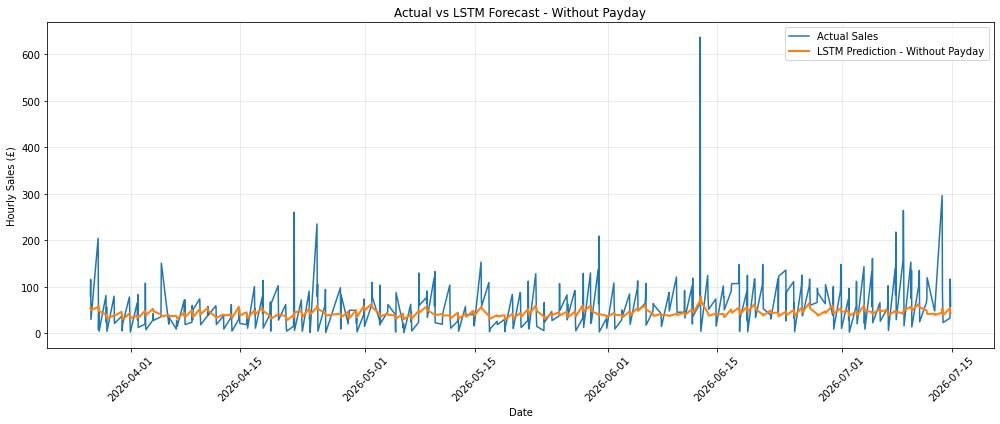

In [84]:
# =========================================================
# STEP 9: Plot LSTM WITHOUT Payday
# Actual vs Predicted Hourly Sales
# =========================================================

import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))

# Actual sales
plt.plot(
    test_times,
    y_test_actual,
    label='Actual Sales',
    linewidth=1.5
)

# LSTM predictions
plt.plot(
    test_times,
    y_pred_actual,
    label='LSTM Prediction - Without Payday',
    linewidth=2
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title('Actual vs LSTM Forecast - Without Payday')

plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

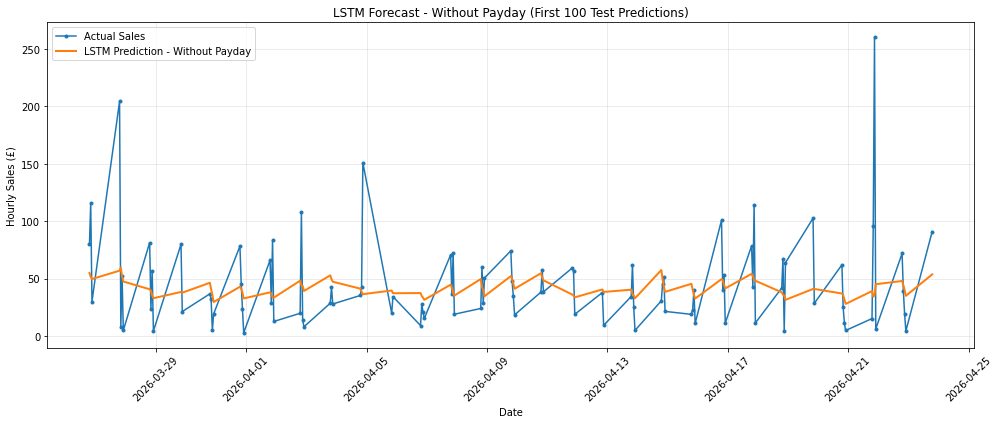

In [85]:
# =========================================================
# Zoomed view - first 100 LSTM test predictions
# =========================================================

n = 100

plt.figure(figsize=(14, 6))

plt.plot(
    test_times[:n],
    y_test_actual[:n],
    label='Actual Sales',
    marker='o',
    markersize=3
)

plt.plot(
    test_times[:n],
    y_pred_actual[:n],
    label='LSTM Prediction - Without Payday',
    linewidth=2
)

plt.xlabel('Date')
plt.ylabel('Hourly Sales (£)')
plt.title('LSTM Forecast - Without Payday (First 100 Test Predictions)')

plt.legend()
plt.xticks(rotation=45)
plt.grid(alpha=0.3)
plt.tight_layout()

plt.show()

In [86]:
# =========================================================
# STEP 10: Prepare LSTM Data WITH Payday Feature
# =========================================================

from sklearn.preprocessing import MinMaxScaler
import numpy as np

# Features WITH payday
lstm_features_payday = [
    'Hourly_Sales',
    'hour',
    'day_of_week',
    'day_of_month',
    'month',
    'is_weekend',
    'payday_window'
]

# Check payday feature exists
print("Payday feature counts:")
print(df['payday_window'].value_counts().sort_index())

# Create dataset
lstm_payday_df = df[
    ['Hours_Start', 'sequence_id'] + lstm_features_payday
].copy()

# Check missing values
print("\nMissing values:")
print(
    lstm_payday_df[lstm_features_payday]
    .isnull()
    .sum()
)

# SAME train/test boundary used previously
print("\nTrain/Test boundary:")
print(split_time)

# Training-period rows only
train_mask_payday = (
    lstm_payday_df['Hours_Start'] < split_time
)

# New scaler because we now have 7 features
scaler_payday = MinMaxScaler()

# Fit ONLY on training data
scaler_payday.fit(
    lstm_payday_df.loc[
        train_mask_payday,
        lstm_features_payday
    ]
)

# Scale full dataset using training scaler
scaled_payday_values = scaler_payday.transform(
    lstm_payday_df[lstm_features_payday]
)

scaled_payday_df = lstm_payday_df.copy()

scaled_payday_df[
    lstm_features_payday
] = scaled_payday_values


print("\nScaled payday dataset shape:")
print(scaled_payday_df.shape)

print("\nNumber of features:")
print(len(lstm_features_payday))

print("\nFirst 5 rows:")
print(scaled_payday_df.head())

Payday feature counts:
0    6587
1    2029
Name: payday_window, dtype: int64

Missing values:
Hourly_Sales     0
hour             0
day_of_week      0
day_of_month     0
month            0
is_weekend       0
payday_window    0
dtype: int64

Train/Test boundary:
2026-03-26 08:00:00

Scaled payday dataset shape:
(8616, 9)

Number of features:
7

First 5 rows:
          Hours_Start  sequence_id  Hourly_Sales    hour  day_of_week  \
0 2024-12-19 16:00:00            1      0.000000  0.6250     0.500000   
1 2024-12-25 12:00:00            2      0.012054  0.3750     0.333333   
2 2024-12-25 13:00:00            2      0.029649  0.4375     0.333333   
3 2024-12-25 14:00:00            2      0.066781  0.5000     0.333333   
4 2024-12-25 15:00:00            2      0.029573  0.5625     0.333333   

   day_of_month  month  is_weekend  payday_window  
0           0.6    1.0         0.0            0.0  
1           0.8    1.0         0.0            0.0  
2           0.8    1.0         0.0           

In [87]:
# =========================================================
# STEP 11: Create LSTM Sequences WITH Payday
# =========================================================

sequence_length = 12

X_payday = []
y_payday = []
target_times_payday = []

# Process each continuous sequence separately
for sequence_id, group in scaled_payday_df.groupby('sequence_id'):

    # Make sure each sequence is chronological
    group = group.sort_values('Hours_Start').reset_index(drop=True)

    # Need at least 13 observations:
    # 12 input hours + 1 target hour
    if len(group) <= sequence_length:
        continue

    feature_values = group[lstm_features_payday].values

    for i in range(sequence_length, len(group)):

        # Previous 12 hours
        X_payday.append(
            feature_values[i-sequence_length:i]
        )

        # Target = Hourly_Sales of next observation
        # Hourly_Sales is column 0
        y_payday.append(
            feature_values[i, 0]
        )

        # Store target timestamp
        target_times_payday.append(
            group.loc[i, 'Hours_Start']
        )


# Convert to numpy arrays
X_payday = np.array(X_payday)
y_payday = np.array(y_payday)
target_times_payday = np.array(target_times_payday)


print("PAYDAY-AWARE LSTM SEQUENCES")
print("----------------------------")

print("X_payday shape:", X_payday.shape)
print("y_payday shape:", y_payday.shape)
print("Target times shape:", target_times_payday.shape)

print("\nEach LSTM sample contains:")
print(X_payday.shape[1], "hours")
print(X_payday.shape[2], "features")

print("\nFirst target time:", target_times_payday[0])
print("Last target time:", target_times_payday[-1])

PAYDAY-AWARE LSTM SEQUENCES
----------------------------
X_payday shape: (1775, 12, 7)
y_payday shape: (1775,)
Target times shape: (1775,)

Each LSTM sample contains:
12 hours
7 features

First target time: 2024-12-28 21:00:00
Last target time: 2026-07-14 21:00:00


In [88]:
# =========================================================
# STEP 12: Train/Test Split for Payday-Aware LSTM
# =========================================================

split_time = pd.Timestamp('2026-03-26 08:00:00')

# Create masks using target timestamps
train_mask_payday = target_times_payday < split_time
test_mask_payday = target_times_payday >= split_time

# Split sequences
X_train_payday = X_payday[train_mask_payday]
X_test_payday = X_payday[test_mask_payday]

y_train_payday = y_payday[train_mask_payday]
y_test_payday = y_payday[test_mask_payday]

# Target timestamps
train_times_payday = target_times_payday[train_mask_payday]
test_times_payday = target_times_payday[test_mask_payday]


print("PAYDAY-AWARE LSTM TRAIN / TEST SPLIT")
print("------------------------------------")

print("X_train_payday shape:", X_train_payday.shape)
print("y_train_payday shape:", y_train_payday.shape)

print("\nX_test_payday shape:", X_test_payday.shape)
print("y_test_payday shape:", y_test_payday.shape)

print("\nTraining target period:")
print(train_times_payday[0], "to", train_times_payday[-1])

print("\nTesting target period:")
print(test_times_payday[0], "to", test_times_payday[-1])

print("\nNumber of training samples:", len(X_train_payday))
print("Number of testing samples:", len(X_test_payday))

print("\nTraining percentage:",
      round(len(X_train_payday) / len(X_payday) * 100, 2), "%")

print("Testing percentage:",
      round(len(X_test_payday) / len(X_payday) * 100, 2), "%")

PAYDAY-AWARE LSTM TRAIN / TEST SPLIT
------------------------------------
X_train_payday shape: (1393, 12, 7)
y_train_payday shape: (1393,)

X_test_payday shape: (382, 12, 7)
y_test_payday shape: (382,)

Training target period:
2024-12-28 21:00:00 to 2026-03-25 22:00:00

Testing target period:
2026-03-26 19:00:00 to 2026-07-14 21:00:00

Number of training samples: 1393
Number of testing samples: 382

Training percentage: 78.48 %
Testing percentage: 21.52 %


In [89]:
# =========================================================
# STEP 13: Build LSTM Model WITH Payday Feature
# =========================================================

from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.optimizers import Adam

# Create model
lstm_model_payday = Sequential([
    
    # LSTM layer
    LSTM(
        64,
        input_shape=(X_train_payday.shape[1],
                     X_train_payday.shape[2])
    ),
    
    # Reduce overfitting
    Dropout(0.2),
    
    # Hidden dense layer
    Dense(32, activation='relu'),
    
    # Output: predicted hourly sales
    Dense(1)
])

# Compile
lstm_model_payday.compile(
    optimizer=Adam(learning_rate=0.001),
    loss='mse',
    metrics=['mae']
)

print("LSTM MODEL WITH PAYDAY")
print("----------------------")

lstm_model_payday.summary()

LSTM MODEL WITH PAYDAY
----------------------
Model: "sequential_1"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 lstm_1 (LSTM)               (None, 64)                18432     
                                                                 
 dropout_1 (Dropout)         (None, 64)                0         
                                                                 
 dense_2 (Dense)             (None, 32)                2080      
                                                                 
 dense_3 (Dense)             (None, 1)                 33        
                                                                 
Total params: 20,545
Trainable params: 20,545
Non-trainable params: 0
_________________________________________________________________


In [90]:
# =========================================================
# STEP 14: Train LSTM WITH Payday Feature
# =========================================================

from tensorflow.keras.callbacks import EarlyStopping

# Early stopping
early_stopping_payday = EarlyStopping(
    monitor='val_loss',
    patience=10,
    restore_best_weights=True,
    verbose=1
)

# Train model
history_payday = lstm_model_payday.fit(
    X_train_payday,
    y_train_payday,
    epochs=100,
    batch_size=32,
    validation_split=0.2,
    callbacks=[early_stopping_payday],
    shuffle=False,
    verbose=1
)

print("\nPAYDAY-AWARE LSTM TRAINING COMPLETED")
print("------------------------------------")

print(
    "Epochs actually trained:",
    len(history_payday.history['loss'])
)

print(
    "Best validation loss:",
    round(min(history_payday.history['val_loss']), 6)
)

print(
    "Best validation MAE (scaled):",
    round(min(history_payday.history['val_mae']), 6)
)

Epoch 1/100
35/35 [==============================] - 4s 30ms/step - loss: 0.0075 - mae: 0.0651 - val_loss: 0.0055 - val_mae: 0.0503
Epoch 2/100
35/35 [==============================] - 0s 14ms/step - loss: 0.0060 - mae: 0.0574 - val_loss: 0.0047 - val_mae: 0.0478
Epoch 3/100
35/35 [==============================] - 0s 13ms/step - loss: 0.0056 - mae: 0.0556 - val_loss: 0.0046 - val_mae: 0.0484
Epoch 4/100
35/35 [==============================] - 1s 14ms/step - loss: 0.0055 - mae: 0.0551 - val_loss: 0.0045 - val_mae: 0.0479
Epoch 5/100
35/35 [==============================] - 0s 14ms/step - loss: 0.0055 - mae: 0.0548 - val_loss: 0.0045 - val_mae: 0.0477
Epoch 6/100
35/35 [==============================] - 0s 14ms/step - loss: 0.0054 - mae: 0.0543 - val_loss: 0.0045 - val_mae: 0.0496
Epoch 7/100
35/35 [==============================] - 1s 15ms/step - loss: 0.0055 - mae: 0.0548 - val_loss: 0.0046 - val_mae: 0.0505
Epoch 8/100
35/35 [==============================] - 0s 14ms/step - loss: 0.

In [91]:
# =========================================================
# STEP 15: Evaluate LSTM WITH Payday on Test Data
# =========================================================

from sklearn.metrics import mean_absolute_error, mean_squared_error
import numpy as np

# Make predictions
y_pred_payday_scaled = lstm_model_payday.predict(X_test_payday).flatten()

# ---------------------------------------------------------
# Convert scaled sales values back to actual £ values
# ---------------------------------------------------------

# Hourly_Sales is the first feature in our scaler
sales_min = scaler_payday.data_min_[0]
sales_max = scaler_payday.data_max_[0]

# Inverse scaling
y_test_payday_actual = (
    y_test_payday * (sales_max - sales_min)
) + sales_min

y_pred_payday_actual = (
    y_pred_payday_scaled * (sales_max - sales_min)
) + sales_min


# ---------------------------------------------------------
# Evaluation metrics
# ---------------------------------------------------------

lstm_payday_mae = mean_absolute_error(
    y_test_payday_actual,
    y_pred_payday_actual
)

lstm_payday_rmse = np.sqrt(
    mean_squared_error(
        y_test_payday_actual,
        y_pred_payday_actual
    )
)


print("LSTM WITH Payday")
print("-----------------")

print("Predictions created:", len(y_pred_payday_actual))
print("Actual test values:", len(y_test_payday_actual))

print("\nMAE: £", round(lstm_payday_mae, 2))
print("RMSE: £", round(lstm_payday_rmse, 2))

print("\nActual sales range:")
print(
    "£", round(y_test_payday_actual.min(), 2),
    "to £", round(y_test_payday_actual.max(), 2)
)

print("\nPredicted sales range:")
print(
    "£", round(y_pred_payday_actual.min(), 2),
    "to £", round(y_pred_payday_actual.max(), 2)
)

12/12 [==============================] - 1s 5ms/step
LSTM WITH Payday
-----------------
Predictions created: 382
Actual test values: 382

MAE: £ 36.39
RMSE: £ 57.52

Actual sales range:
£ 1.29 to £ 636.51

Predicted sales range:
£ 30.33 to £ 65.02


In [92]:
# =========================================================
# STEP 16: Compare LSTM With vs Without Payday
# =========================================================

import pandas as pd

lstm_comparison = pd.DataFrame({
    'Model': [
        'LSTM Without Payday',
        'LSTM With Payday'
    ],
    'MAE': [
        35.01,
        lstm_payday_mae
    ],
    'RMSE': [
        55.41,
        lstm_payday_rmse
    ]
})

lstm_comparison[['MAE', 'RMSE']] = (
    lstm_comparison[['MAE', 'RMSE']].round(2)
)

print("LSTM MODEL COMPARISON")
print("---------------------")
print(lstm_comparison)

# Calculate change caused by payday feature
mae_change = lstm_payday_mae - 35.01
rmse_change = lstm_payday_rmse - 55.41

print("\nEffect of Adding Payday Feature")
print("--------------------------------")
print("MAE change: £", round(mae_change, 2))
print("RMSE change: £", round(rmse_change, 2))

print("\nMAE percentage change:",
      round((mae_change / 35.01) * 100, 2), "%")

print("RMSE percentage change:",
      round((rmse_change / 55.41) * 100, 2), "%")

LSTM MODEL COMPARISON
---------------------
                 Model    MAE   RMSE
0  LSTM Without Payday  35.01  55.41
1     LSTM With Payday  36.39  57.52

Effect of Adding Payday Feature
--------------------------------
MAE change: £ 1.38
RMSE change: £ 2.11

MAE percentage change: 3.95 %
RMSE percentage change: 3.8 %


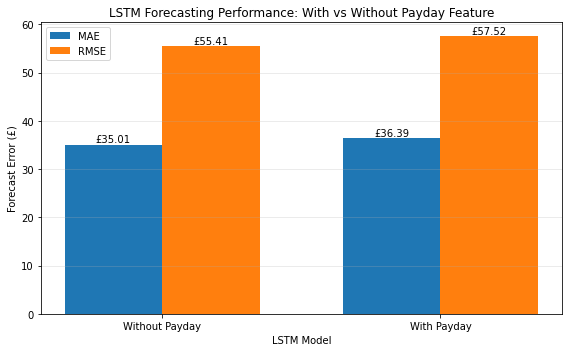

In [93]:
# =========================================================
# STEP 17: LSTM With vs Without Payday Comparison Plot
# =========================================================

import matplotlib.pyplot as plt
import numpy as np

models = ['Without Payday', 'With Payday']

mae_values = [35.01, lstm_payday_mae]
rmse_values = [55.41, lstm_payday_rmse]

x = np.arange(len(models))
width = 0.35

plt.figure(figsize=(8, 5))

bars1 = plt.bar(
    x - width/2,
    mae_values,
    width,
    label='MAE'
)

bars2 = plt.bar(
    x + width/2,
    rmse_values,
    width,
    label='RMSE'
)

# Add values above bars
for bar in bars1:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f'£{bar.get_height():.2f}',
        ha='center'
    )

for bar in bars2:
    plt.text(
        bar.get_x() + bar.get_width()/2,
        bar.get_height() + 0.5,
        f'£{bar.get_height():.2f}',
        ha='center'
    )

plt.xticks(x, models)

plt.ylabel('Forecast Error (£)')
plt.xlabel('LSTM Model')

plt.title(
    'LSTM Forecasting Performance: '
    'With vs Without Payday Feature'
)

plt.legend()
plt.grid(axis='y', alpha=0.3)
plt.tight_layout()

plt.show()

In [94]:
# =========================================================
# STEP 18: Overall Model Results Table
# =========================================================

overall_results = pd.DataFrame({
    'Model': [
        'Naive 7-Day Baseline',
        'Prophet',
        'Prophet',
        'XGBoost',
        'XGBoost',
        'LSTM',
        'LSTM'
    ],

    'Payday_Feature': [
        'No',
        'No',
        'Yes',
        'No',
        'Yes',
        'No',
        'Yes'
    ],

    'MAE': [
        39.56,
        44.13,
        35.52,
        36.36,
        36.37,
        35.01,
        36.39
    ],

    'RMSE': [
        61.56,
        65.24,
        53.56,
        55.29,
        55.25,
        55.41,
        57.52
    ]
})

print("OVERALL FORECASTING RESULTS")
print("---------------------------")
print(overall_results)

OVERALL FORECASTING RESULTS
---------------------------
                  Model Payday_Feature    MAE   RMSE
0  Naive 7-Day Baseline             No  39.56  61.56
1               Prophet             No  44.13  65.24
2               Prophet            Yes  35.52  53.56
3               XGBoost             No  36.36  55.29
4               XGBoost            Yes  36.37  55.25
5                  LSTM             No  35.01  55.41
6                  LSTM            Yes  36.39  57.52


In [95]:
# =========================================================
# STEP 19: Verify Model Test Sets
# =========================================================

print("MODEL TEST-SET VERIFICATION")
print("===========================")

# Prophet
print("\nPROPHET")
print("-------")
print("Samples:", len(prophet_test))
print("Start:", prophet_test['ds'].min())
print("End:", prophet_test['ds'].max())

# XGBoost
print("\nXGBOOST")
print("-------")
print("Samples:", len(test))
print("Start:", test['Hours_Start'].min())
print("End:", test['Hours_Start'].max())

# LSTM
print("\nLSTM")
print("----")
print("Samples:", len(test_times_payday))
print("Start:", test_times_payday[0])
print("End:", test_times_payday[-1])

print("\nLSTM WITHOUT PAYDAY")
print("-------------------")
print("Samples:", len(test_times))
print("Start:", test_times[0])
print("End:", test_times[-1])

MODEL TEST-SET VERIFICATION

PROPHET
-------
Samples: 1724
Start: 2026-03-26 08:00:00
End: 2026-07-15 16:00:00

XGBOOST
-------
Samples: 1531
Start: 2026-03-29 14:00:00
End: 2026-07-15 16:00:00

LSTM
----
Samples: 382
Start: 2026-03-26 19:00:00
End: 2026-07-14 21:00:00

LSTM WITHOUT PAYDAY
-------------------
Samples: 382
Start: 2026-03-26 19:00:00
End: 2026-07-14 21:00:00
